# CNN de variedades de manzanas
Ejecutá las celdas de arriba hacia abajo. La red se entrena desde cero con cuatro variedades de Fruits-360.

Prueba anterior. El entrenamiento y los pesos usados por la demo actual corresponden a `notebooks/01_variedades.ipynb`.

In [34]:
# Librerías
from pathlib import Path
import shutil
import subprocess
import json
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

torch.manual_seed(42)
dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Vamos a usar:', dispositivo)

Vamos a usar: cuda


In [35]:
# Descargar solo las cuatro variedades
originales = Path('/content/fruits360_variedades')
variedades = ['apple_crimson_snow_1', 'apple_granny_smith_1',
             'apple_pink_lady_1', 'apple_red_delicios_1']
version = 'e09de71fa3e80624be016e1b5c90c1c310d046c5'
carpetas = []
for parte in ['Training', 'Validation', 'Test']:
    for variedad in variedades:
        carpetas.append(parte + '/' + variedad)

if not originales.exists():
    subprocess.run(['git', 'clone', '--depth=1', '--filter=blob:none', '--sparse', '--no-checkout',
                    'https://github.com/fruits-360/fruits-360-original-size.git',
                    str(originales)], check=True)
subprocess.run(['git', '-C', str(originales), 'sparse-checkout', 'set'] + carpetas, check=True)
subprocess.run(['git', '-C', str(originales), 'fetch', '--depth=1', 'origin', version], check=True)
subprocess.run(['git', '-C', str(originales), 'checkout', '--detach', version], check=True)
print('Fotos listas.')

Fotos listas.


In [36]:
# Separar las fotos sin mezclar fotogramas consecutivos
datos = Path('/content/manzanas_principiante')
for variedad in variedades:
    fotos = list(originales.glob('*/' + variedad + '/*.jpg'))
    cantidad_r1 = 0
    for foto in fotos:
        if foto.name.startswith('r1_'):
            cantidad_r1 += 1
    mitad = cantidad_r1 // 2

    for foto in fotos:
        rotacion, numero = foto.stem.split('_')
        numero = int(numero)
        if rotacion == 'r0':
            parte = 'entrenamiento'
        elif 16 <= numero < mitad - 16:
            parte = 'validacion'
        elif mitad + 16 <= numero < cantidad_r1 - 16:
            parte = 'prueba'
        else:
            continue
        carpeta = datos / parte / variedad
        carpeta.mkdir(parents=True, exist_ok=True)
        shutil.copy2(foto, carpeta / foto.name)
print('Carpetas de entrenamiento, validación y prueba listas.')

Carpetas de entrenamiento, validación y prueba listas.


In [37]:
# Preparar las imágenes
preparar = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])
aumentar = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(45, translate=(0.05, 0.05), scale=(0.85, 1.1), fill=255),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    preparar,
])
entrenamiento = datasets.ImageFolder(datos / 'entrenamiento', transform=aumentar)
validacion = datasets.ImageFolder(datos / 'validacion', transform=preparar)
prueba = datasets.ImageFolder(datos / 'prueba', transform=preparar)

lotes_entrenamiento = DataLoader(entrenamiento, batch_size=32, shuffle=True)
lotes_validacion = DataLoader(validacion, batch_size=32)
lotes_prueba = DataLoader(prueba, batch_size=32)
nombres = ['Crimson Snow', 'Granny Smith', 'Pink Lady', 'Red Delicious']
print('Entrenamiento:', len(entrenamiento))
print('Validación:', len(validacion))
print('Prueba:', len(prueba))

Entrenamiento: 1241
Validación: 502
Prueba: 502


In [38]:
# Crear la CNN
modelo = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.AdaptiveAvgPool2d((4, 4)),
    nn.Flatten(),
    nn.Linear(1024, 64),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(64, 4),
).to(dispositivo)

error = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001, weight_decay=0.001)
print(modelo)

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): AdaptiveAvgPool2d(output_size=(4, 4))
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=1024, out_features=64, bias=True)
  (12): ReLU()
  (13): Dropout(p=0.5, inplace=False)
  (14): Linear(in_features=64, out_features=4, bias=True)
)


In [39]:
# Entrenar y comprobar validación al terminar cada época
errores_entrenamiento = []
errores_validacion = []
mejor_error = float('inf')
sin_mejora = 0

for epoca in range(40):
    modelo.train()
    error_total = 0
    for imagenes, etiquetas in lotes_entrenamiento:
        imagenes = imagenes.to(dispositivo)
        etiquetas = etiquetas.to(dispositivo)
        optimizador.zero_grad()
        resultado = modelo(imagenes)
        perdida = error(resultado, etiquetas)
        perdida.backward()
        optimizador.step()
        error_total += perdida.item() * len(imagenes)
    error_entrenamiento = error_total / len(entrenamiento)

    modelo.eval()
    error_total = 0
    with torch.no_grad():
        for imagenes, etiquetas in lotes_validacion:
            imagenes = imagenes.to(dispositivo)
            etiquetas = etiquetas.to(dispositivo)
            resultado = modelo(imagenes)
            perdida = error(resultado, etiquetas)
            error_total += perdida.item() * len(imagenes)
    error_validacion = error_total / len(validacion)

    errores_entrenamiento.append(error_entrenamiento)
    errores_validacion.append(error_validacion)
    print('Época', epoca + 1, '| train:', round(error_entrenamiento, 4),
          '| validación:', round(error_validacion, 4))

    if error_validacion < mejor_error - 0.0001:
        mejor_error = error_validacion
        mejor_epoca = epoca + 1
        torch.save(modelo.state_dict(), '/content/cnn_variedades_simple.pth')
        sin_mejora = 0
    else:
        sin_mejora += 1
    if sin_mejora == 7:
        print('Paramos porque validación dejó de mejorar.')
        break
print('Mejor época:', mejor_epoca)

Época 1 | train: 0.8436 | validación: 0.948
Época 2 | train: 0.1805 | validación: 1.2538
Época 3 | train: 0.1453 | validación: 0.7344
Época 4 | train: 0.044 | validación: 0.8769
Época 5 | train: 0.0266 | validación: 1.0406
Época 6 | train: 0.017 | validación: 0.9797
Época 7 | train: 0.0197 | validación: 1.0036
Época 8 | train: 0.0204 | validación: 1.246
Época 9 | train: 0.0321 | validación: 1.7025
Época 10 | train: 0.0325 | validación: 0.6372
Época 11 | train: 0.014 | validación: 0.8155
Época 12 | train: 0.0106 | validación: 0.9109
Época 13 | train: 0.0069 | validación: 1.6682
Época 14 | train: 0.0099 | validación: 1.4935
Época 15 | train: 0.0585 | validación: 1.3583
Época 16 | train: 0.0185 | validación: 0.5042
Época 17 | train: 0.0195 | validación: 1.948
Época 18 | train: 0.0113 | validación: 1.6009
Época 19 | train: 0.0146 | validación: 1.9353
Época 20 | train: 0.0385 | validación: 0.5167
Época 21 | train: 0.0343 | validación: 0.9882
Época 22 | train: 0.0102 | validación: 1.6243
Épo

In [40]:
# Recuperar el mejor modelo
pesos = torch.load('/content/cnn_variedades_simple.pth', map_location=dispositivo, weights_only=True)
modelo.load_state_dict(pesos)
modelo.eval()
print('Mejor modelo cargado.')

Mejor modelo cargado.


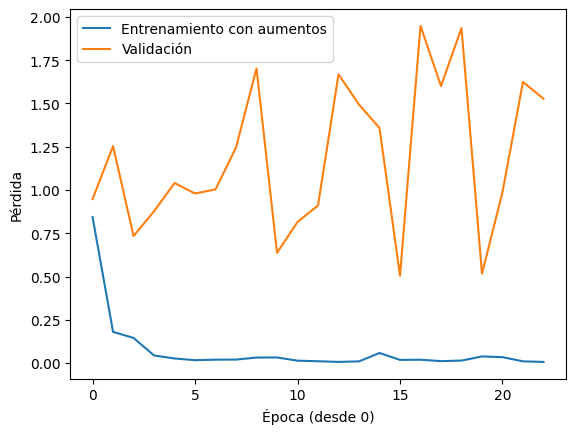

In [41]:
# Comparar entrenamiento y validación
plt.plot(errores_entrenamiento, label='Entrenamiento con aumentos')
plt.plot(errores_validacion, label='Validación')
plt.xlabel('Época (desde 0)')
plt.ylabel('Pérdida')
plt.legend()
plt.savefig('/content/curva_entrenamiento_simple.png')
plt.show()

In [ ]:
# Evaluar el mejor modelo en validación y en prueba
def evaluar(lotes):
    reales = []
    predichas = []
    modelo.eval()
    with torch.no_grad():
        for imagenes, etiquetas in lotes:
            imagenes = imagenes.to(dispositivo)
            resultado = modelo(imagenes)
            prediccion = resultado.argmax(dim=1)
            reales.extend(etiquetas.tolist())
            predichas.extend(prediccion.cpu().tolist())
    return classification_report(reales, predichas, target_names=nombres, digits=3, zero_division=0)

print('VALIDACIÓN')
print(evaluar(lotes_validacion))
print('PRUEBA')
print(evaluar(lotes_prueba))

VALIDACIÓN


In [ ]:
# Guardar los nombres y las pérdidas junto con los pesos
with open('/content/clases_variedades_simple.json', 'w') as archivo:
    json.dump(nombres, archivo)
with open('/content/perdidas_variedades_simple.json', 'w') as archivo:
    json.dump([errores_entrenamiento, errores_validacion], archivo)
print('Pesos: cnn_variedades_simple.pth')
print('Clases: clases_variedades_simple.json')

Usamos vistas de las mismas frutas. Aunque dé un puntaje alto, falta probar con otras manzanas de variedad conocida.

Datos: [Fruits-360, Mihai Oltean](https://github.com/fruits-360/fruits-360-original-size/tree/e09de71fa3e80624be016e1b5c90c1c310d046c5), [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).